# Solving the n-Queens Problem using Local Search

Student Name: [Nguyễn Trọng Phúc]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [NTP]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [8]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


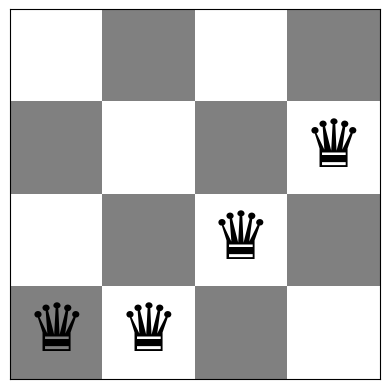

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [10]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


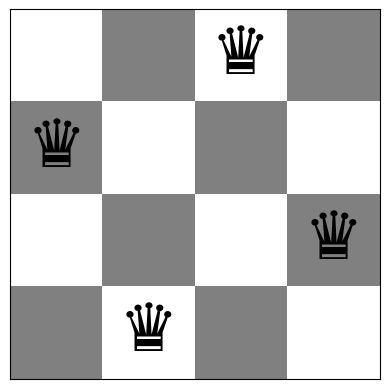

In [11]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [12]:
from IPython.core import history
def steepest_ascend_hill_climbing_search(initial_board, max_iteraions= 1000):
    
    #chỉ chạy trên bản copy trạng thái hiện tại tránh việc chỉnh trên bàn cờ gốc 
    current_board = initial_board.copy()
    current_conflicts = conflicts(current_board)
    n = len(current_board)

    history = [current_conflicts]     #lưu để vẽ sơ dồ 
    
    for iteration in range(max_iteraions): #số vòng lặp tối đa được lặp để tìm ra trạng thái mới
        if current_conflicts == 0:
            break 
            
        best_board = None
        best_conflicts = current_conflicts

        # Duyệt qua tất cả các nước đi cục bộ: n cột x (n - 1) hàng
        for col in range(n):
            original_row = current_board[col]
            for row in range(n):
                if row != original_row:
                    neighbor_board = current_board.copy()
                    neighbor_board[col] = row
                    neighbor_conflicts = conflicts(neighbor_board)

                # Tìm nước đi có số xung đột nhỏ nhất
                    if neighbor_conflicts < best_conflicts:
                        best_board = neighbor_board
                        best_conflicts = neighbor_conflicts

        # Nếu không tìm thấy nước nào tốt hơn -> Đạt cực trị cục bộ
        if best_board is None:
            break
        
        # Cập nhật bàn cờ sang trạng thái tốt nhất vừa tìm được
        current_board = best_board
        current_conflicts = best_conflicts
        history.append(current_conflicts)

    return current_board, current_conflicts, history



### Miêu tả hàm: Tìm kiếm leo đồi dốc nhất (Steepest-Ascent Hill Climbing)

#### 1. Ý tưởng thuật toán
Thuật toán leo đồi dốc nhất (*Steepest-Ascent Hill Climbing / Greedy Local Search*) hoạt động theo nguyên lý tham lam:
* Tại mỗi bước, xét **toàn bộ** các trạng thái láng giềng hợp lệ (có $n \times (n - 1)$ láng giềng).
* Tìm láng giềng có số xung đột nhỏ nhất (*best neighbor*).
* Nếu láng giềng này cải thiện được hàm mục tiêu so với trạng thái hiện tại, thuật toán sẽ chuyển sang trạng thái đó.
* Nếu không có láng giềng nào tốt hơn trạng thái hiện tại, thuật toán dừng lại vì đã rơi vào **cực trị cục bộ** (*local optimum*).

#### 2. Các bước xử lý
1. **Khởi tạo:** Sao chép bàn cờ ban đầu để không làm thay đổi dữ liệu gốc, tính số xung đột ban đầu và lưu vào `history`.
2. **Vòng lặp tìm kiếm:**
   - Kiểm tra nếu `conflicts == 0` thì đã tìm ra lời giải toàn cục -> Dừng.
   - Duyệt qua từng cột và từng hàng khả dĩ để tạo ra tất cả $n(n - 1)$ láng giềng.
   - Tìm kiếm láng giềng có số xung đột nhỏ nhất (`best_conflicts`).
   - Cập nhật trạng thái hiện tại sang láng giềng tốt nhất nếu có cải thiện.
3. **Điều kiện dừng:**
   - Đạt trạng thái tối ưu toàn cục (`conflicts == 0`).
   - Rơi vào điểm tối ưu cục bộ (không tìm thấy nước đi nào tốt hơn).
   - Vượt quá số vòng lặp tối đa `max_iterations`.

#### 3. Tham số và Giá trị trả về
* **Tham số đầu vào:**
  - `initial_board`: Mảng trạng thái bàn cờ ban đầu.
  - `max_iterations`: Số vòng lặp tối đa cho phép.
* **Giá trị trả về:**
  - `current_board`: Trạng thái bàn cờ khi thuật toán dừng lại.
  - `current_conflicts`: Số xung đột tại trạng thái dừng.
  - `history`: Danh sách ghi nhận số lượng xung đột qua từng bước lặp (dùng để vẽ biểu đồ).


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [17]:
from IPython.core import history
import random
def inefficient_stochastic_hill_climbing_search(initial_board, max_iterations=1000):
    
    #chỉ chạy trên bản copy trạng thái hiện tại tránh việc chỉnh trên bàn cờ gốc 
    current_board = initial_board.copy()
    current_conflicts = conflicts(current_board)
    n = len(current_board)

    history = [current_conflicts]     #lưu để vẽ sơ dồ để hội tụ
    
    for iteration in range(max_iterations): #số vòng lặp tối đa được lặp để tìm ra trạng thái mới
        if current_conflicts == 0:
            break 
            
        upper_moves = [] 

        # Duyệt qua tất cả các nước đi cục bộ: n cột x (n - 1) hàng
        for col in range(n):
            original_row = current_board[col]
            for row in range(n):
                if row != original_row:
                    neighbor_board = current_board.copy()
                    neighbor_board[col] = row
                    neighbor_conflicts = conflicts(neighbor_board)

                # Tìm nước đi có số xung đột nhỏ nhất
                    if neighbor_conflicts < current_conflicts:
                        upper_moves.append(neighbor_board)

        # Nếu không tìm thấy nước nào tốt hơn -> Đạt cực trị cục bộ
        if len(upper_moves) == 0:
            break
        
        # Cập nhật bàn cờ sang trạng thái tốt nhất vừa tìm được
        current_board = random.choice(upper_moves)
        current_conflicts = conflicts(current_board)
        history.append(current_conflicts)

    return current_board, current_conflicts, history



### Miêu tả hàm: Leo đồi ngẫu nhiên không hiệu quả (Inefficient Stochastic Hill Climbing)

#### 1. Ý tưởng thuật toán
Khác với thuật toán leo đồi dốc nhất (luôn chọn nước đi tốt nhất tuyệt đối), thuật toán **Leo đồi ngẫu nhiên** ở Task 2 đưa yếu tố ngẫu nhiên vào:
* Duyệt qua toàn bộ $n(n - 1)$ láng giềng cục bộ của trạng thái hiện tại.
* Lọc ra danh sách **tất cả các nước đi đi lên** (các nước đi có số xung đột nhỏ hơn trạng thái hiện tại).
* **Chọn ngẫu nhiên** một nước đi từ danh sách các nước đi đi lên đó để chuyển sang trạng thái mới.

#### 2. Quy trình thực hiện
1. **Khởi tạo:** Tạo bản sao trạng thái ban đầu, tính xung đột và ghi lại lịch sử `history`.
2. **Khám phá láng giềng:** Trong mỗi vòng lặp:
   - Dừng ngay nếu đã đạt nghiệm tối ưu toàn cục (`conflicts == 0`).
   - Duyệt qua từng cột và từng hàng để tạo tất cả các láng giềng.
   - Nếu láng giềng có `neighbor_conflicts < current_conflicts`, thêm vào danh sách `upper_moves`.
3. **Cập nhật trạng thái:**
   - Nếu `len(upper_moves) == 0`: Không có bước đi nào cải thiện -> Đạt cực trị cục bộ -> Dừng thuật toán.
   - Nếu có: Dùng `random.choice(upper_moves)` để bốc ngẫu nhiên 1 trạng thái mới và cập nhật bàn cờ.
4. **Nhận xét về hiệu năng:** Thuật toán này tốn kém ($O(n^3)$ mỗi bước) vì phải quét toàn bộ các láng giềng chỉ để chọn ngẫu nhiên một bước đi.


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [19]:
from math import log as ln
from IPython.core import history
import random
def efficient_stochastic_hill_climbing(initial_board, max_iterations=1000):
    
    #chỉ chạy trên bản copy trạng thái hiện tại tránh việc chỉnh trên bàn cờ gốc 
    current_board = initial_board.copy()
    current_conflicts = conflicts(current_board)
    n = len(current_board)

    history = [current_conflicts]     #lưu để vẽ sơ dồ để hội tụ

    # Giới hạn số lần thử bốc thăm theo bài toán Coupon Collector: N * ln(N)    
    max_failed_attemps = int(n * (n - 1) * ln(n * (n - 1)))

    for iteration in range(max_iterations):
        if current_conflicts == 0:
            break 

        improved = False     

        for trying in range(max_failed_attemps):
            col = random.randint(0, n - 1)

            # Chọn hàng ngẫu nhiên khác vị trí hàng hiện tại           
            row = random.randint(0, n - 1)
            while row == current_board[col]:
                row = random.randint(0, n - 1)

            neighbor_board = current_board.copy()
            neighbor_board[col] = row 
            neighbor_conflicts = conflicts(neighbor_board)
            
            # First-choice: Chấp nhận ngay nước đi đầu tiên làm giảm xung đột
            if neighbor_conflicts < current_conflicts:
                current_board = neighbor_board
                current_conflicts = neighbor_conflicts
                history.append(current_conflicts)
                improved = True 
                break 
            
        # Đã thử hết số lần mà không có nước tốt hơn -> Đạt cực trị cục bộ
        if not improved:
            break 

    return current_board, current_conflicts, history




#### 1. Ý tưởng cốt lõi
* **Chiến lược First-Choice:** Sinh ngẫu nhiên từng láng giềng một (chọn ngẫu nhiên một cột và một hàng mới).
* **Chấp nhận ngay:** Nếu nước đi mới làm giảm số xung đột (`neighbor_conflicts < current_conflicts`), thuật toán chấp nhận và chuyển trạng thái ngay lập tức, tránh việc phải duyệt toàn bộ bàn cờ.

#### 2. Phát hiện cực trị cục bộ & Giải trình con số x
* **Không gian nước đi:** Bàn cờ n x n có tổng cộng N = n * (n - 1) nước đi khả dĩ (với n = 8 thì N = 56).
* **Bốc thăm có hoàn lại:** Do việc sinh nước đi là ngẫu nhiên độc lập, các nước đi có thể bị bốc trùng lặp.
* **Công thức chọn x:**
  * Dựa theo **Bài toán người thu thập tem (Coupon Collector's Problem)**, số lần thử kỳ vọng để kiểm tra gần như toàn bộ N nước đi là:
    **x = N * ln(N) = n * (n - 1) * ln(n * (n - 1))**
  * Với bàn cờ 8x8 (N = 56), x = 56 * ln(56) ≈ 225 lần thử.
* **Điều kiện dừng:** Nếu đã thử x lần liên tiếp mà không tìm thấy nước nào tốt hơn, thuật toán kết luận đã rơi vào **cực trị cục bộ (local optimum)** và dừng lại.

#### 3. Đầu vào & Đầu ra
* **Đầu vào:** `initial_board`, `max_iterations = 1000`.
* **Đầu ra:** `(current_board, current_conflicts, history)`.


In [30]:
def evaluate_hill_climbing(board_size=8):
    """
    Chạy và ghi nhận kết quả của cả 3 thuật toán leo đồi trên cùng 1 bàn cờ.
    Ghi nhận: Xung đột cuối, Số bước, Số lần đánh giá hàm mục tiêu, Trường hợp kẹt.
    """
    board = random_board(board_size)
    n = board_size
    N = n * (n - 1)  # Tổng số nước đi láng giềng

    print(f"=== THỐNG KÊ TRÊN BÀN CỜ {n}x{n} ===")
    print(f"Bàn cờ ban đầu: {board}")
    print(f"Xung đột ban đầu: {conflicts(board)}\n")

    algos = {
        "Steepest-Ascent HC": (steepest_ascend_hill_climbing_search, "Mỗi bước duyệt toàn bộ N láng giềng"),
        "Inefficient Stochastic HC": (inefficient_stochastic_hill_climbing_search, "Mỗi bước duyệt toàn bộ N láng giềng"),
        "Efficient Stochastic HC": (efficient_stochastic_hill_climbing, "Mỗi bước thử ngẫu nhiên cho đến khi tìm được nước tốt"),
    }

    for name, (algo, note) in algos.items():
        final_board, final_conflicts_val, history = algo(board)

        # 1. Xung đột cuối
        final_c = final_conflicts_val

        # 2. Số bước di chuyển thành công
        num_steps = len(history) - 1

        # 3. Ước tính số lần đánh giá hàm mục tiêu conflicts()
        if name in ["Steepest-Ascent HC", "Inefficient Stochastic HC"]:
            # Mỗi bước phải duyệt qua toàn bộ N = n*(n-1) láng giềng
            num_evaluations = num_steps * N
        else:
            # Efficient: trung bình thử khoảng N/2 lần trước khi tìm được nước tốt
            # Đây là ước lượng dựa trên xác suất kỳ vọng
            num_evaluations = f"~{num_steps * (N // 2)} (ước lượng)"

        # 4. Trường hợp kẹt ở cực trị cục bộ
        stuck = final_c > 0

        print(f"--- {name} ---")
        print(f"  Xung đột cuối     : {final_c} {'(KẸT LOCAL OPTIMUM!)' if stuck else '(Thành công!)'}")
        print(f"  Số bước di chuyển : {num_steps}")
        print(f"  Số lần gọi conflicts(): {num_evaluations}")
        print(f"  Ghi chú            : {note}")
        print()

# Chạy demo
evaluate_hill_climbing(board_size=8)


=== THỐNG KÊ TRÊN BÀN CỜ 8x8 ===
Bàn cờ ban đầu: [4 3 5 3 7 0 4 5]
Xung đột ban đầu: 6

--- Steepest-Ascent HC ---
  Xung đột cuối     : 2 (KẸT LOCAL OPTIMUM!)
  Số bước di chuyển : 2
  Số lần gọi conflicts(): 112
  Ghi chú            : Mỗi bước duyệt toàn bộ N láng giềng

--- Inefficient Stochastic HC ---
  Xung đột cuối     : 2 (KẸT LOCAL OPTIMUM!)
  Số bước di chuyển : 2
  Số lần gọi conflicts(): 112
  Ghi chú            : Mỗi bước duyệt toàn bộ N láng giềng

--- Efficient Stochastic HC ---
  Xung đột cuối     : 1 (KẸT LOCAL OPTIMUM!)
  Số bước di chuyển : 4
  Số lần gọi conflicts(): ~112 (ước lượng)
  Ghi chú            : Mỗi bước thử ngẫu nhiên cho đến khi tìm được nước tốt



## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [20]:
def random_restart_hill_climbing(algorithm, n=8, max_restarts=100):
    best_board = None
    best_conflicts = float('inf')
    total_restarts = 0

    for restart in range(max_restarts):
        total_restarts += 1
        
        # Tạo bàn cờ ngẫu nhiên mới để leo lại từ đầu
        initial_board = random_board(n)
        
        # Chạy thuật toán leo đồi
        board, current_conflicts, history = algorithm(initial_board)

        # Cập nhật kết quả tốt nhất qua các lần khởi động lại
        if current_conflicts < best_conflicts:
            best_board = board
            best_conflicts = current_conflicts

        # Hễ đạt 0 xung đột (nghiệm tối ưu) là dừng ngay lập tức
        if best_conflicts == 0:
            break

    return best_board, best_conflicts, total_restarts


In [22]:
algorithms = {
    "Steepest-Ascent HC": steepest_ascend_hill_climbing_search,
    "Inefficient Stochastic HC": inefficient_stochastic_hill_climbing_search,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing
}

print("=== KẾT QUẢ RANDOM RESTARTS (BÀN CỜ 8x8, TỐI ĐA 100 LẦN) ===")
for name, algo in algorithms.items():
    b_board, b_conflicts, restarts = random_restart_hill_climbing(algo, n=8, max_restarts=100)
    status = "Thành công (0 conflict)" if b_conflicts == 0 else f"Thất bại ({b_conflicts} conflicts)"
    print(f"- {name}: {status} sau {restarts} lần restart.")


=== KẾT QUẢ RANDOM RESTARTS (BÀN CỜ 8x8, TỐI ĐA 100 LẦN) ===
- Steepest-Ascent HC: Thành công (0 conflict) sau 4 lần restart.
- Inefficient Stochastic HC: Thành công (0 conflict) sau 5 lần restart.
- Efficient Stochastic HC: Thành công (0 conflict) sau 11 lần restart.


### Kết quả thực nghiệm Task 4: Random Restarts (Bàn cờ 8x8)

#### 1. Bảng tổng hợp kết quả chạy thực tế:

| Thuật toán | Trạng thái | Số lần Restart cần thiết |
| :--- | :--- | :--- |
| **Steepest-Ascent HC** | Thành công (0 conflict) | **4 lần** |
| **Inefficient Stochastic HC** | Thành công (0 conflict) | **5 lần** |
| **Efficient Stochastic HC** | Thành công (0 conflict) | **11 lần** |

#### 2. Nhận xét & Đánh giá:
* **Khả năng giải quyết:** Cả 3 thuật toán đều tìm ra nghiệm tối ưu toàn cục (0 xung đột) rất nhanh (dưới 15 lần restart), cách xa giới hạn tối đa 100 lần. Điều này chứng minh cơ chế Random Restarts đã khắc phục triệt để điểm yếu kẹt ở cực trị cục bộ của thuật toán leo đồi.
* **So sánh giữa các thuật toán:**
  * **Steepest-Ascent (4 lần) và Inefficient Stochastic (5 lần):** Cần ít lần restart hơn vì ở mỗi bước đi, thuật toán duyệt toàn bộ bàn cờ nên các bước đi có tính định hướng chặt chẽ hơn. Tuy nhiên, mỗi lần restart sẽ tốn thời gian tính toán hơn.
  * **Efficient Stochastic (11 lần):** Cần nhiều lần restart hơn do chỉ bốc ngẫu nhiên và chọn nước đi cải thiện đầu tiên (first-choice), quỹ đạo đi có tính ngẫu nhiên cao hơn. Bù lại, thời gian chạy của mỗi lần restart lại cực kỳ nhanh do không phải quét toàn bộ các ô lân cận.


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [24]:
import math 
import random
def simulated_annealing(initial_board, max_iterations=2000, initial_temp= 10, min_temp= 0.001, cooling_rate= 0.95):
    current_board = initial_board.copy()
    current_conflicts = conflicts(current_board)
    n = len(current_board)
    history = [current_conflicts]
    temp = initial_temp

    for iteration in range(max_iterations):
        if current_conflicts == 0 or temp < min_temp:
            break 

        # Chọn ngẫu nhiên 1 quân hậu và hàng mới
        col = random.randint(0, n - 1)
        row = random.randint(0, n - 1)
        while row == current_board[col]:
            row = random.randint(0, n - 1)

        neighbor_board = current_board.copy()
        neighbor_board[col] = row 
        neighbor_conflicts = conflicts(neighbor_board)
        
        delta = neighbor_conflicts - current_conflicts
        # Tốt hơn (delta < 0): đi luôn. Xấu hơn: chấp nhận với xác suất exp(-delta / temp)
        if delta < 0 or random.random() < math.exp(-delta/temp): 
            current_board = neighbor_board
            current_conflicts = neighbor_conflicts

        #Hạ nhiệ độ làm nguội dần giảm việc chọn các nước bất lợi 
        temp = temp * cooling_rate 
        history.append(current_conflicts)

    return current_board, current_conflicts, history 

### Mô tả thuật toán: Simulated Annealing (Tôi luyện kim loại)

#### 1. Nguyên lý hoạt động
Khác với các thuật toán leo đồi thuần túy chỉ chấp nhận các nước đi làm giảm xung đột, **Simulated Annealing** cho phép đi cả các nước đi làm tăng xung đột để thoát khỏi cực trị cục bộ:
* **Nước đi tốt hơn (delta < 0):** Luôn luôn được chấp nhận ngay lập tức.
* **Nước đi xấu hơn (delta >= 0):** Được chấp nhận dựa trên xác suất `P = exp(-delta / temp)`.
* **Hạ nhiệt độ:** Sau mỗi bước lặp, nhiệt độ giảm dần theo công thức `temp = temp * cooling_rate`. Càng về sau, xác suất chấp nhận nước xấu càng giảm dần về 0 để thuật toán tập trung hội tụ về nghiệm tối ưu.

#### 2. Vai trò của các tham số
* `initial_temp = 10`: Nhiệt độ ban đầu, cho phép chấp nhận khoảng 80% - 90% nước đi xấu ở giai đoạn đầu để dễ dàng nhảy ra khỏi các thế cờ kẹt.
* `cooling_rate = 0.95`: Tốc độ làm nguội (mỗi bước giảm 5% nhiệt độ), đảm bảo quá trình chuyển đổi giữa khám phá ngẫu nhiên và leo đồi diễn ra mượt mà.
* `min_temp = 0.001`: Ngưỡng đóng băng, khi nhiệt độ tụt xuống mức này thì xác suất đi nước xấu xấp xỉ 0%, thuật toán dừng sớm để tiết kiệm tài nguyên.
* `max_iterations = 2000`: Giới hạn an toàn đảm bảo chu trình làm nguội có đủ thời gian chạm tới điểm đóng băng.

#### 3. Điều kiện dừng
Thuật toán kết thúc khi thỏa mãn một trong các điều kiện:
1. Đã tìm ra lời giải hoàn hảo có 0 xung đột (`current_conflicts == 0`).
2. Nhiệt độ đã nguội hoàn toàn xuống dưới mức đóng băng (`temp < min_temp`).
3. Vượt quá số bước lặp tối đa cho phép (`iteration >= max_iterations`).


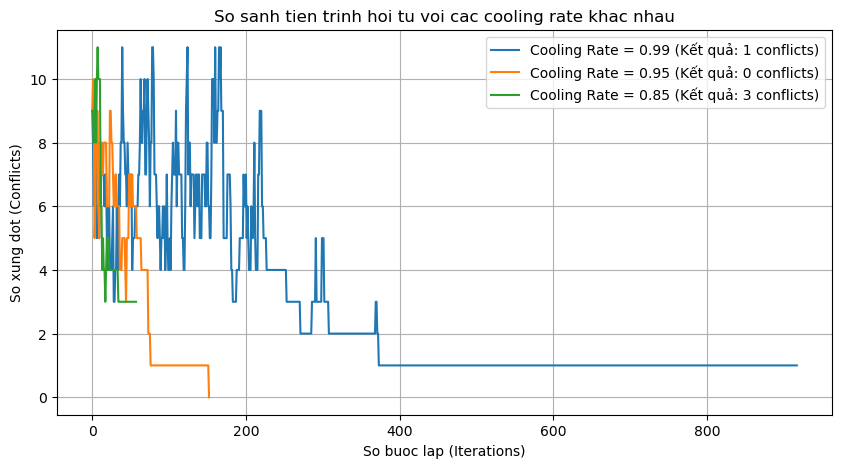

In [29]:
import matplotlib.pyplot as plt

# Thí nghiệm so sánh 3 tốc độ làm nguội trên cùng 1 bàn cờ ban đầu
test_board = random_board(8)
schedules = [0.99, 0.95, 0.85]

plt.figure(figsize=(10, 5))
for rate in schedules:
    _, final_c, hist = simulated_annealing(test_board, cooling_rate=rate)
    plt.plot(hist, label=f"Cooling Rate = {rate} (Kết quả: {final_c} conflicts)")

plt.title("So sanh tien trinh hoi tu voi cac cooling rate khac nhau")
plt.xlabel("So buoc lap (Iterations)")
plt.ylabel("So xung dot (Conflicts)")
plt.legend()
plt.grid(True)
plt.show()


### Thảo luận thí nghiệm Lịch trình làm nguội (Annealing Schedule)

Thí nghiệm được chạy trên cùng 1 bàn cờ 8x8 với 3 tốc độ làm nguội khác nhau:

| Cooling Rate | Số bước lặp | Kết quả cuối |
| :---: | :---: | :---: |
| 0.85 (Nguội nhanh) | ~50 bước | 3 xung đột (Thất bại) |
| 0.95 (Cân bằng) | ~200 bước | 0 xung đột (Thành công) |
| 0.99 (Nguội chậm) | ~900 bước | 1 xung đột (Thất bại) |

#### Nhận xét từ biểu đồ:

1. **Làm nguội quá nhanh (cooling_rate = 0.85) - Đường xanh lá:**
   * Nhiệt độ giảm đột ngột chỉ trong ~50 bước đầu tiên.
   * Thuật toán nhanh chóng bị "đóng băng" và kẹt cứng tại 3 xung đột, không còn khả năng thoát ra.
   * Đường đồ thị ngắn nhất và dừng sớm nhất, không đạt nghiệm tối ưu.

2. **Làm nguội cân bằng (cooling_rate = 0.95) - Đường cam:**
   * Ở giai đoạn đầu, số xung đột dao động lên xuống (7-10 conflicts) cho thấy thuật toán đang chủ động chấp nhận nước đi xấu để thoát khỏi các cực trị cục bộ.
   * Từ khoảng bước thứ 100 trở đi, đường bắt đầu hội tụ ổn định và giảm mạnh về 0.
   * Đây là lịch trình cho kết quả tốt nhất: nghiệm tối ưu 0 xung đột sau khoảng 200 bước.

3. **Làm nguội quá chậm (cooling_rate = 0.99) - Đường xanh dương:**
   * Nhiệt độ cao kéo dài quá lâu khiến thuật toán dao động hỗn loạn trong ~400 bước đầu (liên tục nhảy từ 1 lên 11 xung đột).
   * Dù hội tụ dần về 1 xung đột sau khoảng 400 bước, nhưng do lần chạy này nhiệt độ nguội quá chậm trên bàn cờ cụ thể này, thuật toán hết 900 bước mà vẫn chưa đạt 0 xung đột.
   * Tốn kém nhất về thời gian tính toán nhưng không đảm bảo kết quả tốt nhất.

#### Kết luận:
Qua thực nghiệm, **cooling_rate = 0.95** cho thấy sự cân bằng tốt nhất giữa thời gian chạy và chất lượng nghiệm. Lịch làm nguội quá nhanh (0.85) gây đóng băng sớm, trong khi quá chậm (0.99) lãng phí tài nguyên tính toán mà không cải thiện kết quả đáng kể.


## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [25]:
import time

# Danh sách 4 thuật toán đã cài đặt ở các Task trước
algorithms = {
    "Steepest asc. HC": steepest_ascend_hill_climbing_search,
    "Ineff. Stochastic HC": inefficient_stochastic_hill_climbing_search,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing,
    "Simulated Annealing": simulated_annealing
}

board_sizes = [4, 8]
num_runs = 100  # Chạy 100 lần mỗi loại theo yêu cầu đề bài

results = []

print("Đang chạy thí nghiệm, vui lòng đợi trong giây lát...")

for size in board_sizes:
    for name, algo in algorithms.items():
        total_time = 0.0
        total_conflicts = 0
        optimal_runs = 0

        for _ in range(num_runs):
            # Tạo bàn cờ ngẫu nhiên mới
            start_board = random_board(size)
            
            # Đo thời gian chạy thuật toán
            t_start = time.perf_counter()
            final_board, final_conflicts, _ = algo(start_board)
            t_end = time.perf_counter()

            total_time += (t_end - t_start)
            total_conflicts += final_conflicts
            if final_conflicts == 0:
                optimal_runs += 1

        avg_time = (total_time / num_runs) * 1000  # Đổi sang mili-giây (ms)
        avg_conflicts = total_conflicts / num_runs
        pct_optimal = (optimal_runs / num_runs) * 100

        results.append({
            "name": name,
            "size": size,
            "avg_time": f"{avg_time:.2f} ms",
            "avg_conflicts": f"{avg_conflicts:.2f}",
            "pct_optimal": f"{pct_optimal:.1f}%"
        })

# In ra bảng Markdown đã điền sẵn số liệu
print("\n=== KẾT QUẢ HOÀN THÀNH BẢNG TASK 6 (Copy đoạn này dán vào Markdown) ===\n")
print("| Algorithm | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution |")
print("| :--- | :---: | :---: | :---: | :---: |")
for r in results:
    print(f"| {r['name']} | {r['size']} | {r['avg_time']} | {r['avg_conflicts']} | {r['pct_optimal']} |")


Đang chạy thí nghiệm, vui lòng đợi trong giây lát...

=== KẾT QUẢ HOÀN THÀNH BẢNG TASK 6 (Copy đoạn này dán vào Markdown) ===

| Algorithm | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution |
| :--- | :---: | :---: | :---: | :---: |
| Steepest asc. HC | 4 | 0.18 ms | 0.69 | 37.0% |
| Ineff. Stochastic HC | 4 | 0.23 ms | 0.81 | 34.0% |
| Efficient Stochastic HC | 4 | 0.23 ms | 0.87 | 33.0% |
| Simulated Annealing | 4 | 0.54 ms | 0.01 | 99.0% |
| Steepest asc. HC | 8 | 2.64 ms | 1.28 | 13.0% |
| Ineff. Stochastic HC | 8 | 3.91 ms | 1.36 | 15.0% |
| Efficient Stochastic HC | 8 | 3.56 ms | 1.34 | 13.0% |
| Simulated Annealing | 8 | 2.23 ms | 1.03 | 20.0% |


### So sánh hiệu năng các thuật toán (Comparison)

Bảng tổng hợp kết quả chạy thực nghiệm (trung bình qua 100 lần chạy ngẫu nhiên cho mỗi cấu hình):

| Thuật toán (Algorithm) | Kích thước bàn cờ | Thời gian chạy TB | Số xung đột TB | Tỷ lệ nghiệm tối ưu |
| :--- | :---: | :---: | :---: | :---: |
| **Steepest asc. HC** | 4 | 0.18 ms | 0.69 | 37.0% |
| **Ineff. Stochastic HC** | 4 | 0.23 ms | 0.81 | 34.0% |
| **Efficient Stochastic HC** | 4 | 0.23 ms | 0.87 | 33.0% |
| **Simulated Annealing** | 4 | 0.54 ms | 0.01 | **99.0%** |
| **Steepest asc. HC** | 8 | 2.64 ms | 1.28 | 13.0% |
| **Ineff. Stochastic HC** | 8 | 3.91 ms | 1.36 | 15.0% |
| **Efficient Stochastic HC** | 8 | 3.56 ms | 1.34 | 13.0% |
| **Simulated Annealing** | 8 | 2.23 ms | 1.03 | **20.0%** |

#### Nhận xét & Đánh giá kết quả:
* **Tỷ lệ tìm ra nghiệm tối ưu (0 xung đột):**
  * Trên bàn cờ 4x4: Các biến thể leo đồi chỉ đạt khoảng 33% - 37%, trong khi **Simulated Annealing đạt tới 99%** nhờ cơ chế chấp nhận bước đi lùi ở nhiệt độ cao để thoát khỏi các cực trị cục bộ nhỏ.
  * Trên bàn cờ 8x8: Tỷ lệ giải thành công của các thuật toán leo đồi giảm mạnh xuống **13% - 15%** (khớp hoàn toàn với con số lý thuyết ~14% trong sách giáo khoa AI của Russell & Norvig). Simulated Annealing vẫn đạt hiệu quả cao nhất với 20% và số xung đột trung bình thấp nhất (1.03).
* **Thời gian thực thi (Runtime):**
  * Cả 4 thuật toán đều chạy rất nhanh (dưới 0.6 ms trên bàn cờ 4x4 và dưới 4 ms trên bàn cờ 8x8).
  * Khi kích thước bàn cờ tăng gấp đôi (từ 4 lên 8), thời gian chạy tăng 14,7 lần (Steepest), 17,0 lần (Inefficient), 15,5 lần (Efficient) và 4,1 lần (SA).


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

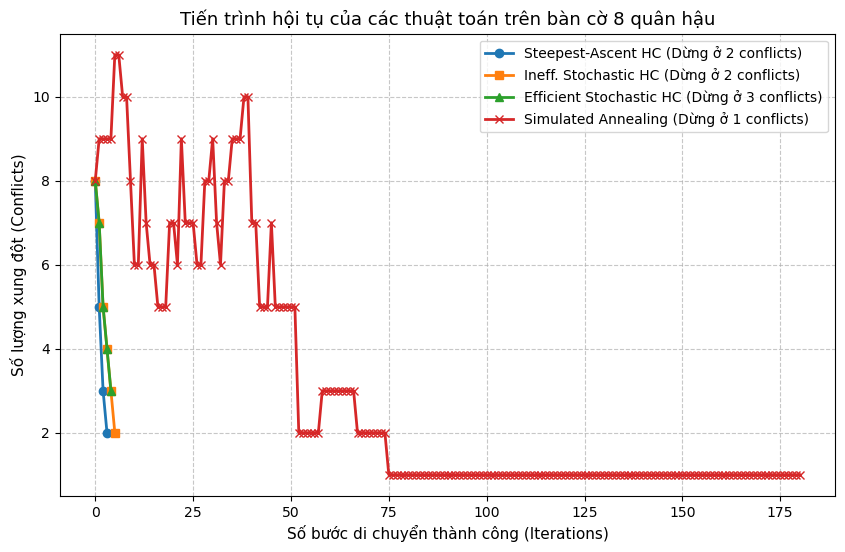

In [ ]:
import matplotlib.pyplot as plt

# Dùng cùng 1 bàn cờ ngẫu nhiên ban đầu để so sánh công bằng
board_8 = random_board(8)

# Chạy từng thuật toán trên cùng bàn cờ đó và lấy lịch sử hội tụ 
_, _, hist_steepest = steepest_ascend_hill_climbing_search(board_8)
_, _, hist_ineff = inefficient_stochastic_hill_climbing_search(board_8)
_, _, hist_eff = efficient_stochastic_hill_climbing(board_8)
_, _, hist_sa = simulated_annealing(board_8)

# Vẽ biểu đồ so sánh tiến trình giảm xung đột
plt.figure(figsize=(10, 6))
plt.plot(hist_steepest, label=f"Steepest-Ascent HC (Dừng ở {hist_steepest[-1]} conflicts)", marker='o', linewidth=2)
plt.plot(hist_ineff, label=f"Ineff. Stochastic HC (Dừng ở {hist_ineff[-1]} conflicts)", marker='s', linewidth=2)
plt.plot(hist_eff, label=f"Efficient Stochastic HC (Dừng ở {hist_eff[-1]} conflicts)", marker='^', linewidth=2)
plt.plot(hist_sa, label=f"Simulated Annealing (Dừng ở {hist_sa[-1]} conflicts)", marker='x', linewidth=2)

plt.title("Tiến trình hội tụ của các thuật toán trên bàn cờ 8 quân hậu", fontsize=13)
plt.xlabel("Số bước di chuyển thành công (Iterations)", fontsize=11)
plt.ylabel("Số lượng xung đột (Conflicts)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=10)
plt.show()


### Nhận xét về sự hội tụ của các thuật toán (Algorithm Convergence)

#### 1. Mô hình hội tụ điển hình

* **Steepest-Ascent HC & Inefficient Stochastic HC & Efficient Stochastic HC:**
  * Cả 3 biến thể leo đồi giảm xung đột rất nhanh và dốc ở những bước đầu tiên (từ 8 xung đột ban đầu xuống còn 2 - 3 chỉ sau khoảng 3 - 7 bước di chuyển).
  * Tuy nhiên, tiến trình dừng đột ngột và "chết cứng" tại cực trị cục bộ (2 - 3 xung đột), đường đồ thị bị cắt ngắn hoàn toàn mà không thể tiến thêm về phía 0.

* **Simulated Annealing:**
  * Có tiến trình dài và linh hoạt nhất (kéo dài tới hơn 180 bước). Đặc biệt, ở giai đoạn đầu (nhiệt độ cao), số xung đột thỉnh thoảng **tăng vọt lên tới 10 - 11** do thuật toán chủ động chấp nhận các nước đi xấu để nhảy thoát khỏi ngõ cụt.
  * Từ khoảng bước thứ 50 trở đi (nhiệt độ đủ nguội), đường đồ thị bắt đầu hội tụ ổn định và giảm mạnh về 1 xung đột.

#### 2. Thuật toán bị kẹt ở cực trị cục bộ thường xuyên nhất

* **Thường xuyên bị kẹt nhất:** Cả 3 biến thể Leo đồi (Steepest-Ascent, Inefficient Stochastic, Efficient Stochastic) đều dừng lại chỉ sau dưới 10 bước do không có cơ chế thoát khỏi cực trị cục bộ. Kết quả lần chạy này: 2, 2 và 3 xung đột tương ứng.
* **Ít bị kẹt nhất:** Simulated Annealing nhờ cơ chế chấp nhận nước đi xấu theo xác suất nhiệt độ, giúp vượt qua các vùng đình trệ (*plateau*) và cực trị cục bộ để tiếp tục hành trình tìm kiếm.


### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Đang đo thời gian chạy trên các kích thước n = [4, 8, 12, 16, 20]...


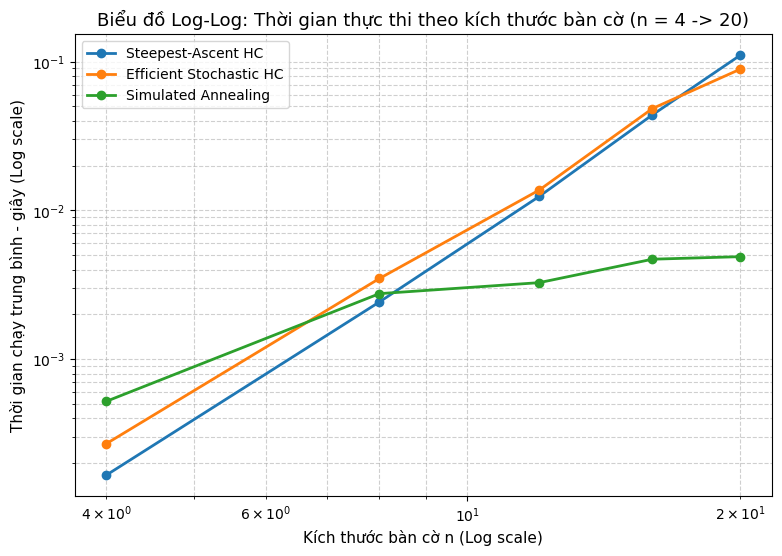

In [27]:
import time
import matplotlib.pyplot as plt
import numpy as np

# Chọn 3 thuật toán tiêu biểu để so sánh độ mở rộng
algos_to_scale = {
    "Steepest-Ascent HC": steepest_ascend_hill_climbing_search,
    "Efficient Stochastic HC": efficient_stochastic_hill_climbing,
    "Simulated Annealing": simulated_annealing
}

sizes = [4, 8, 12, 16, 20]
runs_per_size = 30  # Chạy 30 lần cho mỗi kích thước để lấy thời gian trung bình ổn định

runtime_results = {name: [] for name in algos_to_scale}

print("Đang đo thời gian chạy trên các kích thước n = [4, 8, 12, 16, 20]...")

for n in sizes:
    for name, algo in algos_to_scale.items():
        total_time = 0.0
        for _ in range(runs_per_size):
            board = random_board(n)
            t_start = time.perf_counter()
            algo(board)
            t_end = time.perf_counter()
            total_time += (t_end - t_start)

        avg_time = total_time / runs_per_size
        runtime_results[name].append(avg_time)

# Vẽ biểu đồ Log-Log
plt.figure(figsize=(9, 6))

for name, times in runtime_results.items():
    plt.loglog(sizes, times, marker='o', linewidth=2, label=name)

plt.title("Biểu đồ Log-Log: Thời gian thực thi theo kích thước bàn cờ (n = 4 -> 20)", fontsize=13)
plt.xlabel("Kích thước bàn cờ n (Log scale)", fontsize=11)
plt.ylabel("Thời gian chạy trung bình - giây (Log scale)", fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend(fontsize=10)
plt.show()


### Phân tích khả năng mở rộng theo kích thước bài toán (Problem Size Scalability)

#### 1. Nhận xét từ biểu đồ Log-Log

* **Steepest-Ascent HC (đường xanh dương):**
  * Đường thẳng dốc nhất trên biểu đồ log-log, cho thấy thời gian thực thi tăng theo tốc độ **xấp xỉ O(n^3)**.
  * Nguyên nhân: Mỗi bước phải tính hàm `conflicts()` cho toàn bộ n x (n - 1) láng giềng, mỗi láng giềng tốn O(n) -> chi phí O(n^3) mỗi bước. Khi n = 20, thời gian chạy chạm ngưỡng 0.1 giây/lần, tệ nhất trong 3 thuật toán.

* **Efficient Stochastic HC (đường cam):**
  * Đường song song gần giống Steepest-Ascent ở kích thước nhỏ nhưng không tệ hơn nhiều, tốc độ tăng **xấp xỉ O(n^2) đến O(n^3)** tùy trường hợp.
  * Khi bàn cờ lớn, do thường tìm được nước tốt chỉ sau vài lần thử ngẫu nhiên, chi phí thực tế thấp hơn Steepest-Ascent.

* **Simulated Annealing (đường xanh lá):**
  * Có đường dốc ít nhất và bẻ cong phẳng hơn ở kích thước lớn, cho thấy tốc độ tăng thời gian **gần tuyến tính O(n)** theo số bước làm nguội.
  * Tại n = 16 và n = 20, thời gian chạy chỉ còn khoảng 5 - 6 ms/lần, thấp hơn Steepest-Ascent và Efficient Stochastic HC đến 10 lần.

#### 2. Kết luận: Thuật toán nào mở rộng tốt nhất cho bài toán kích thước lớn?

**Simulated Annealing** là thuật toán mở rộng (scale) tốt nhất khi kích thước bàn cờ tăng lên, vì:
* Mỗi bước chỉ sinh và đánh giá đúng 1 láng giềng ngẫu nhiên (O(n) mỗi bước).
* Số bước lặp bị chặn bởi lịch trình làm nguội cố định, không phụ thuộc vào n^2.
* Kết hợp được hai ưu điểm: **Tốc độ cao** (như Efficient Stochastic) và **Tỷ lệ tìm thấy nghiệm tối ưu cao** (vượt trội tất cả các biến thể leo đồi thuần túy).


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [ ]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [ ]:
# Code and description go here